In [102]:
# Put imports here
import numpy as np
import scipy as sp
from scipy import stats, special
import matplotlib as mp
import matplotlib.pyplot as plt
import mp2lib as ml

SEED = 1320312820 # drawn 2026-10-29, do not change
rng = np.random.default_rng(SEED)
rng_1, rng_2, rng_3, rng_4, rng_5, rng_6, rng_7, rng_8, rng_A, rng_B = rng.spawn(10)

## Step 1
Work with four distributions: uniform on [0,1], exponential with rate 1, standard Gaussian, and Rayleigh with scale 1.

### 1. For each, write the CDF and the PDF in a Markdown cell, and state the support.

*Uniform [0,1]:*

PDF:
$$
f_X(x) =
\begin{cases}
    \frac{1}{b-a} & \text{if }\text{ } a \leq x \leq b
    \\ 0, & \text{else}
\end{cases}
$$

CDF:

$$
F_X(x) = P(X \leq x) =  
\begin{cases}
    0 & \text{if }\text{ } x < 0
    \\ x & \text{if }\text{ } 0 \leq x \leq 1 
    \\ 1 & \text{if }\text{ } x \geq 1
\end{cases}
$$

*Exponential with rate 1:*

PDF: 
$$
f_X(x) =
\begin{cases}
    e^{-x} & \text{if }\text{ } x < 0
    \\ 0 & \text{else }
\end{cases}
$$

CDF:

$$
F_X(x) = P(X \leq x) = 
\begin{cases}
    1 - e^{-x} & \text{if }\text{ } x < 0
    \\ 0 & \text{else }
\end{cases}
$$

*Standard Gaussian:*

PDF: 
$$
f_Z(z) = \frac{1}{\sqrt{2\pi}} e^{-z^2/2} \ \ \text{for } z \ \epsilon \ \mathbb{R}
\\ \text{where } z = \frac{x-\mu}{\sigma}
$$

CDF:

$$
\Phi(z) = \frac{1}{\sqrt{2\pi}} \int_{-\infty}^{z} e^{-u^2/2} \,du  \ \ \text{for } z \ \epsilon \ \mathbb{R}
\\ \text{where } z = \frac{x-\mu}{\sigma}
$$

*Rayleigh with scale 1:*

PDF: 
$$
f_X(x;\sigma=1) = x e^{-x^2/(2)} \ \ \text{for } x \geq 0
$$

CDF:

$$
F_X(x;\sigma=1) = 1 - e^{-x^2/(2)} \ \ \text{for } x \ \epsilon \ [0,\infty)
$$

### 2. Generate 10<sup>5</sup> samples of each with the library generators.

In [103]:
# Generating 10^5 samples of each function
n = 10 ** 5

unif = rng_1.random(size=n)
expo = rng_1.exponential(scale=1.0, size=n)
gau = rng_1.standard_normal(size=n)
ray = rng_1.rayleigh(scale=1.0, size=n)

# print("Uniform [0,1]\t\t\tExponential w/ Rate 1\t\tStandard Gaus\t\t\tRayleigh scale 1")
# print("----------------------------------------------------------------------------------------------------------------------")
# for i in range(0, n, 1): 
#     print(unif[i], end="\t\t")
#     print(expo[i], end="\t\t")
#     print(gau[i], end="\t\t")
#     print(ray[i])

### 3. Plot the empirical CDF against the analytic CDF for each.

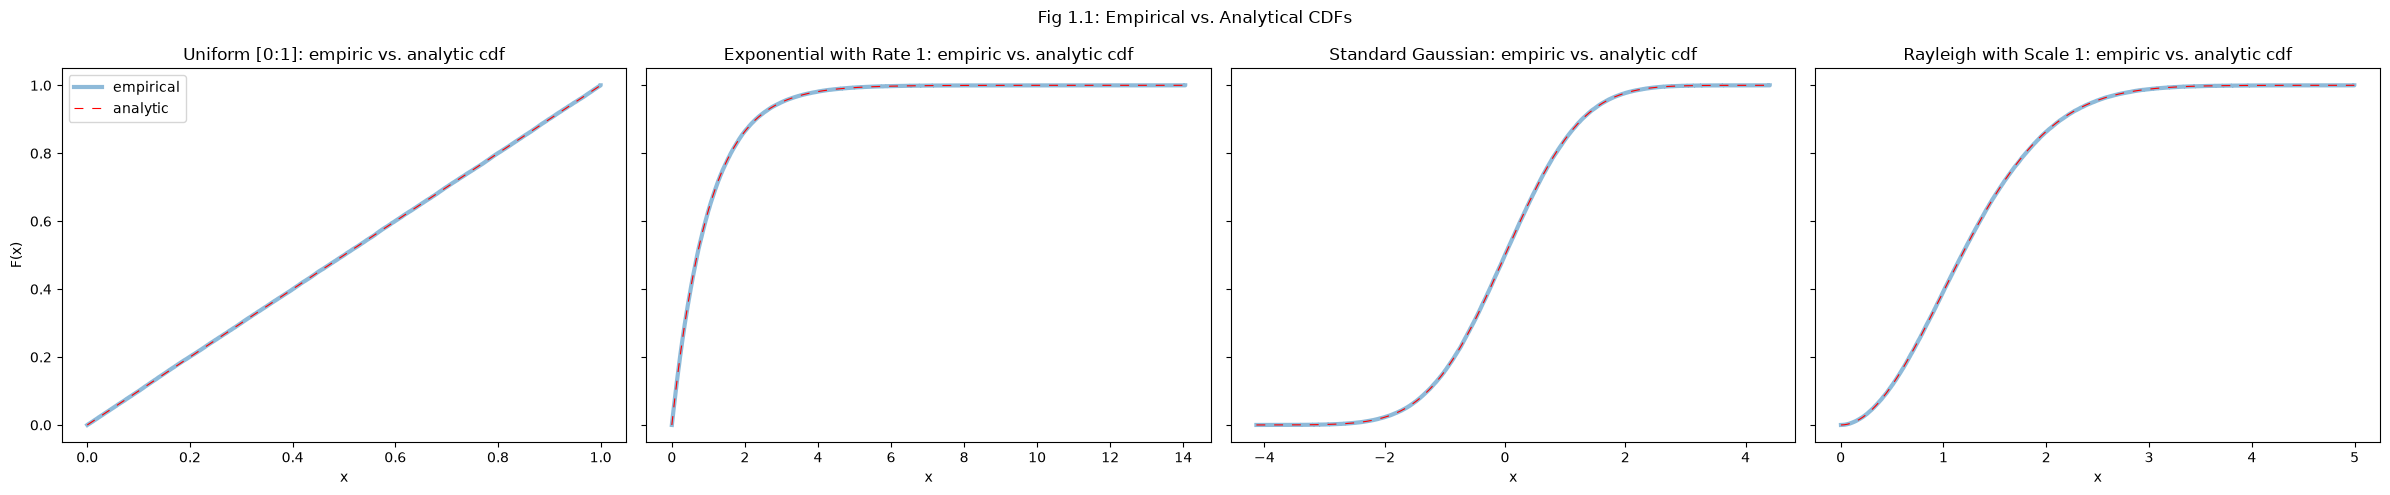

In [104]:
# name -> (samples, analytic CDF)
dists = {
    "Uniform [0:1]":            (unif,      stats.uniform),
    "Exponential with Rate 1":  (expo,   stats.expon),
    "Standard Gaussian":        (gau,       stats.norm),
    "Rayleigh with Scale 1":    (ray,       stats.rayleigh),
}

def ecdf(x):
    xs = np.sort(x)
    ys = np.arange(1, len(xs) + 1) / len(xs)
    return xs, ys

fig, axes = plt.subplots(1, 4, figsize=(24, 5), sharey=True)

for ax, (name, (x, dist)) in zip(axes, dists.items()):
    xs, ys = ecdf(x)
    grid = np.linspace(xs[0], xs[-1], 500)

    ax.step(xs, ys, where="post", lw=3, alpha=0.5, label="empirical")
    ax.plot(grid, dist.cdf(grid), "r--", lw=.8, dashes=(8, 8), label="analytic")
    ax.set_title(f"{name}: empiric vs. analytic cdf")
    ax.set_xlabel("x")

axes[0].set_ylabel("F(x)")
axes[0].legend()
fig.suptitle("Fig 1.1: Empirical vs. Analytical CDFs")
fig.tight_layout()
plt.show()

### 4. Plot a normalized histogram against the analytic pdf for each.

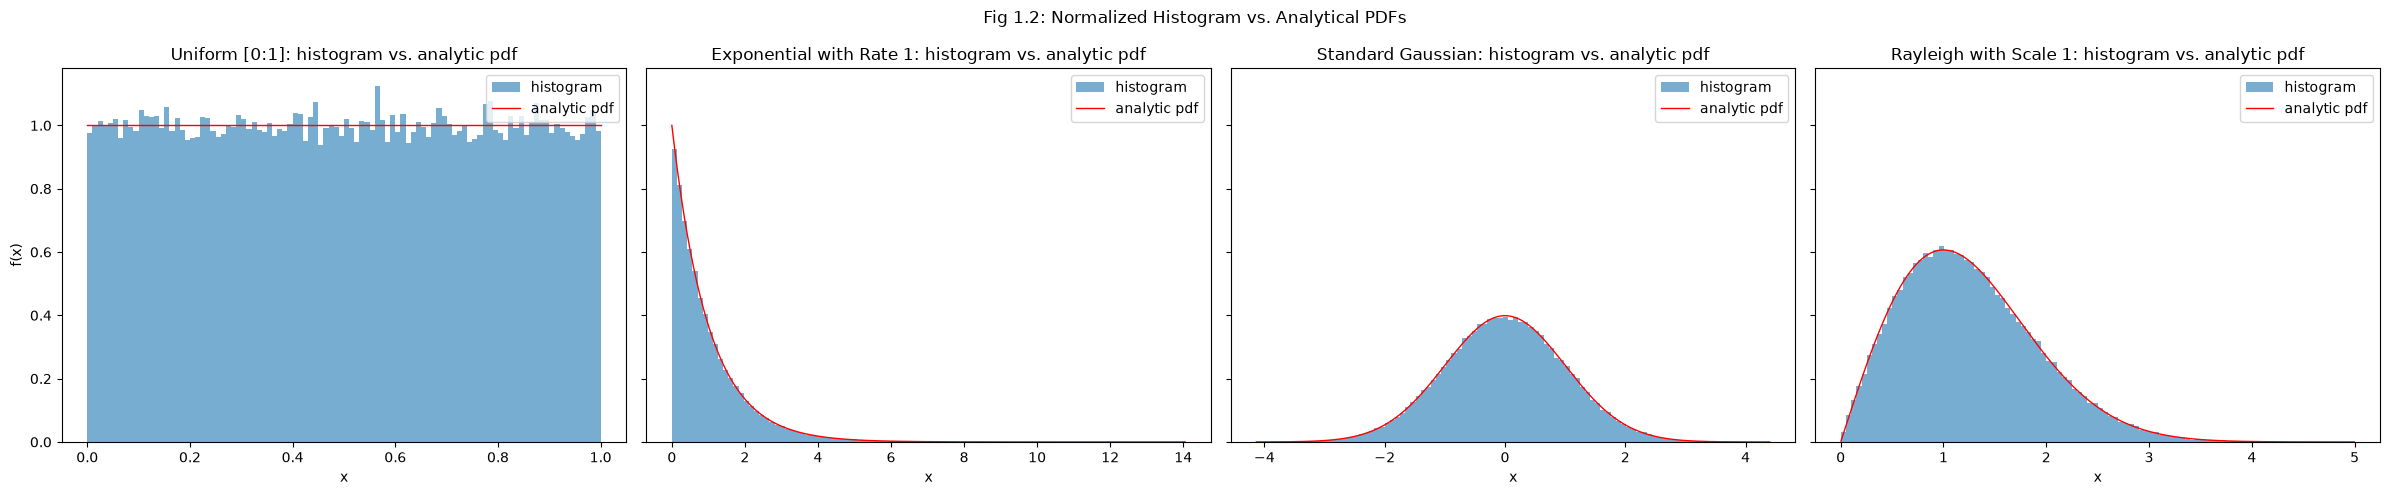

In [105]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5), sharey=True)

for ax, (name, (x, dist)) in zip(axes, dists.items()):
    grid = np.linspace(x.min(), x.max(), 500)
    
    ax.hist(x, bins=100, density=True, alpha=0.6, label="histogram")
    ax.plot(grid, dist.pdf(grid), "r-", lw=1, label="analytic pdf")
    ax.set_title(f"{name}: histogram vs. analytic pdf")
    ax.set_xlabel("x")
    ax.legend()


axes[0].set_ylabel("f(x)")
axes[0].legend()
fig.suptitle("Fig 1.2: Normalized Histogram vs. Analytical PDFs")
fig.tight_layout()
plt.show()

### 5. Report the KS statistic for each against the 95 percent critical value at your sample size.

In [106]:
from scipy.stats import ksone

# Calculating KS statistic and p values
uniform_ks_stat = ml.ks_statistic(unif, stats.uniform.cdf)
exponential_ks_stat= ml.ks_statistic(expo, stats.expon.cdf)
gaussian_ks_stat = ml.ks_statistic(gau, stats.norm.cdf)
rayleigh_ks_stat = ml.ks_statistic(ray, stats.rayleigh.cdf)

# Calculating the 95% critical value
crit_val = ksone.ppf(1 - (1 - 0.95) / 2, n)

print("KS Statistics:\n" + "-" * 75)

# Conditional Reports based on KS Stat vs Crit Val
print(f"KS Critical Value (95%):                   {crit_val:>31.6f}\n")

print(f"Empirical Samples of Uniform [0:1]:        {uniform_ks_stat     :>20.6f} \u2264 {crit_val:.6f}")
print(f"Empirical Samples of Exponential w/ Rate 1:{exponential_ks_stat :>20.6f} \u2264 {crit_val:.6f}")
print(f"Empirical Samples of Standard Gaussian:    {gaussian_ks_stat    :>20.6f} \u2264 {crit_val:.6f}")
print(f"Empirical Samples of Rayleigh w/ Rate 1:   {rayleigh_ks_stat    :>20.6f} \u2264 {crit_val:.6f}")
print("-" * 75)


BOLD = '\033[1m'
RESET = '\033[0m'

# Uniform [0,1]
if(uniform_ks_stat <= crit_val):
    print(f"Uniform [0:1]: \n KS Statistic of {BOLD}{uniform_ks_stat:.6f}{RESET} is less than or equal to the 95% critical value." +
          f"\n The sample data does follow the theoretical uniform distribution.\n")
else:
    print(f"Uniform [0:1]: \n KS Statistic of {BOLD}{uniform_ks_stat:.6f}{RESET} is greater than the 95% critical value." +
          f"\n The sample data does not follow the theoretical uniform distribution.\n")

# Exponential Rate 1
if(exponential_ks_stat <= crit_val):
    print(f"Exponential with Rate 1: \n KS Statistic of {BOLD}{exponential_ks_stat:.6f}{RESET} is less than or equal to the 95% critical value." +
          f"\n The sample data does follow the theoretical uniform distribution.\n")
else:
    print(f"Exponential with Rate 1: \n KS Statistic of {BOLD}{exponential_ks_stat:.6f}{RESET} is greater than the 95% critical value." +
          f"\n The sample data does not follow the theoretical uniform distribution.\n")

# Standard Gaussian
if(gaussian_ks_stat <= crit_val):
    print(f"Standard Gaussian: \n KS Statistic of {BOLD}{gaussian_ks_stat:.6f}{RESET} is less than or equal to the 95% critical value." +
          f"\n The sample data does follow the theoretical uniform distribution.\n")
else:
    print(f"Standard Gaussian: \n KS Statistic of {BOLD}{gaussian_ks_stat:.6f}{RESET} is greater than the 95% critical value." +
          f"\n The sample data does not follow the theoretical uniform distribution.\n")

# Rayleigh w/ Scale 1
if(rayleigh_ks_stat <= crit_val):
    print(f"Rayleigh with Rate 1: \n KS Statistic of {BOLD}{rayleigh_ks_stat:.6f}{RESET} is less than or equal to the 95% critical value." +
          f"\n The sample data does follow the theoretical uniform distribution.\n")
else:
    print(f"Rayleigh with Rate 1: \n KS Statistic of {BOLD}{rayleigh_ks_stat:.6f}{RESET} is greater than the 95% critical value." +
          f"\n The sample data does not follow the theoretical uniform distribution.\n")

KS Statistics:
---------------------------------------------------------------------------
KS Critical Value (95%):                                          0.004293

Empirical Samples of Uniform [0:1]:                    0.001744 ≤ 0.004293
Empirical Samples of Exponential w/ Rate 1:            0.003000 ≤ 0.004293
Empirical Samples of Standard Gaussian:                0.001579 ≤ 0.004293
Empirical Samples of Rayleigh w/ Rate 1:               0.002857 ≤ 0.004293
---------------------------------------------------------------------------
Uniform [0:1]: 
 KS Statistic of 0.001744 is less than or equal to the 95% critical value.
 The sample data does follow the theoretical uniform distribution.

Exponential with Rate 1: 
 KS Statistic of 0.003000 is less than or equal to the 95% critical value.
 The sample data does follow the theoretical uniform distribution.

Standard Gaussian: 
 KS Statistic of 0.001579 is less than or equal to the 95% critical value.
 The sample data does follow the t

### 6. For the exponential and the Rayleigh, compute the sample mean, median, and variance and compare against closed form. State all six closed forms.

**Theoretical Values**

---

*Exponential:*

Mean: $\frac{1}{\lambda} = 1$

Median: $\frac{ln(2)}{\lambda} = 0.6931$

Variance: $\frac{1}{\lambda^2} = 1$

---

*Rayleigh:*

Mean: $\sigma\sqrt{\frac{\pi}{2}} = 1.253$

Median: $\sigma\sqrt{2\ln(2)} = 1.177$

Variance: $\sigma^2(2-\frac{\pi}{2}) = 	0.4292$

In [107]:
expo_mean, expo_med, expo_var = stats.expon.mean(), stats.expon.median(), stats.expon.var()
ray_mean, ray_med, ray_var = stats.rayleigh.mean(), stats.rayleigh.median(), stats.rayleigh.var()

expo_mean_sim, expo_med_sim, expo_var_sim = expo.mean(), np.median(expo), expo.var()
ray_mean_sim, ray_med_sim, ray_var_sim = ray.mean(), np.median(ray), ray.var()

def percent_err(theo, sim):
    return 100 * np.abs(theo - sim) / theo

# Exponential close + sample mean, median, variance, and %error
print( "Exponential Closed Form"       +  "  | Exponential Sample Form"                + f"  | % error\n" +
       "-" * 63 + "\n" +
      f"Mean =     {expo_mean:>12.4f}" + f"  | Mean \u2248     {expo_mean_sim:>12.4f}" + f"  | {percent_err(expo_mean, expo_mean_sim):.4f} %\n" +
      f"Median =   {expo_med :>12.4f}" + f"  | Median \u2248   {expo_med_sim :>12.4f}" + f"  | {percent_err(expo_med,  expo_med_sim ):.4f} %\n" +
      f"Variance = {expo_var :>12.4f}" + f"  | Variance \u2248 {expo_var_sim :>12.4f}" + f"  | {percent_err(expo_var,  expo_var_sim ):.4f} %\n\n")

# Rayleigh closed + sample mean, median, variance, and %error
print("Rayleigh Closed Form   "        +  "  | Rayleigh Sample Form   "                + f"  | % error\n" +
      "-" * 63 + "\n" +
      f"Mean =     {ray_mean :>12.4f}" + f"  | Mean \u2248     {ray_mean_sim :>12.4f}" + f"  | {percent_err(ray_mean,  ray_mean_sim):.4f} %\n" +
      f"Median =   {ray_med  :>12.4f}" + f"  | Median \u2248   {ray_med_sim  :>12.4f}" + f"  | {percent_err(ray_med,   ray_med_sim ):.4f} %\n" +
      f"Variance = {ray_var  :>12.4f}" + f"  | Variance \u2248 {ray_var_sim  :>12.4f}" + f"  | {percent_err(ray_var,   ray_var_sim ):.4f} %")

Exponential Closed Form  | Exponential Sample Form  | % error
---------------------------------------------------------------
Mean =           1.0000  | Mean ≈           1.0026  | 0.2609 %
Median =         0.6931  | Median ≈         0.6941  | 0.1332 %
Variance =       1.0000  | Variance ≈       0.9963  | 0.3692 %


Rayleigh Closed Form     | Rayleigh Sample Form     | % error
---------------------------------------------------------------
Mean =           1.2533  | Mean ≈           1.2551  | 0.1432 %
Median =         1.1774  | Median ≈         1.1778  | 0.0297 %
Variance =       0.4292  | Variance ≈       0.4326  | 0.7936 %


### 7. The exponential mean and median differ by a factor of about 1.44 while the Gaussian mean and median coincide. Explain in two sentences what property of the density causes that.

The Gaussian mean and median coincide due to the distribution's symmetry, causing an even half of the data to be on each the left and right side and the two values to sit at the middle. In contrast, the exponential mean and median differ due to its right-skewed behavior, causing the mean to shift to where most of the data is while the median stays at the center.

## Step 2

### Question 1

$F_{F^{-1}(U)}(x)=P(F^{-1}(U) \leq x)\text{, take the CDF of both sides of the inequality =>}$

$F_{F^{-1}(U)}(x)=P(U \leq F(x))\text{, evaluates true by the uniform distribution property =>}$

$\text{QED}$

### Question 2

Exponential:

$q = F(x) = 1 - e^{-\lambda x}$

$e^{-\lambda x} = 1 - q$

$-\lambda x = ln(1 - q)$

$x = F^{-1}(q) = -\frac{ln(1 - q)}{\lambda}$

<br>

Rayleigh:

$q = F(x) = 1 - e^{-\frac{x^{2}}{2 \sigma^{2}}}$

$e^{-\frac{x^{2}}{2 \sigma^{2}}} = 1 - q$

$-\frac{x^{2}}{2 \sigma^{2}} = ln(1 - q)$

$x^{2} = -2 \sigma^{2} ln(1 - q)$

$x = F^{-1}(q) = \sigma \sqrt{-2ln(1 - q)}$

### Question 3

In [108]:
n = 10 ** 5

inv_cdf_exp = ml.sample_by_inversion(ml.inv_cdf_exponential, n, rng_2)
inv_cdf_ray = ml.sample_by_inversion(ml.inv_cdf_rayleigh, n, rng_2)

### Question 4

In [109]:
ks_exp = ml.ks_statistic(inv_cdf_exp, stats.expon.cdf)
ks_ray = ml.ks_statistic(inv_cdf_ray, stats.rayleigh.cdf)

print(f"D_exp = {ks_exp:.6f}")
print(f"D_ray = {ks_ray:.6f}")

D_exp = 0.001726
D_ray = 0.002870


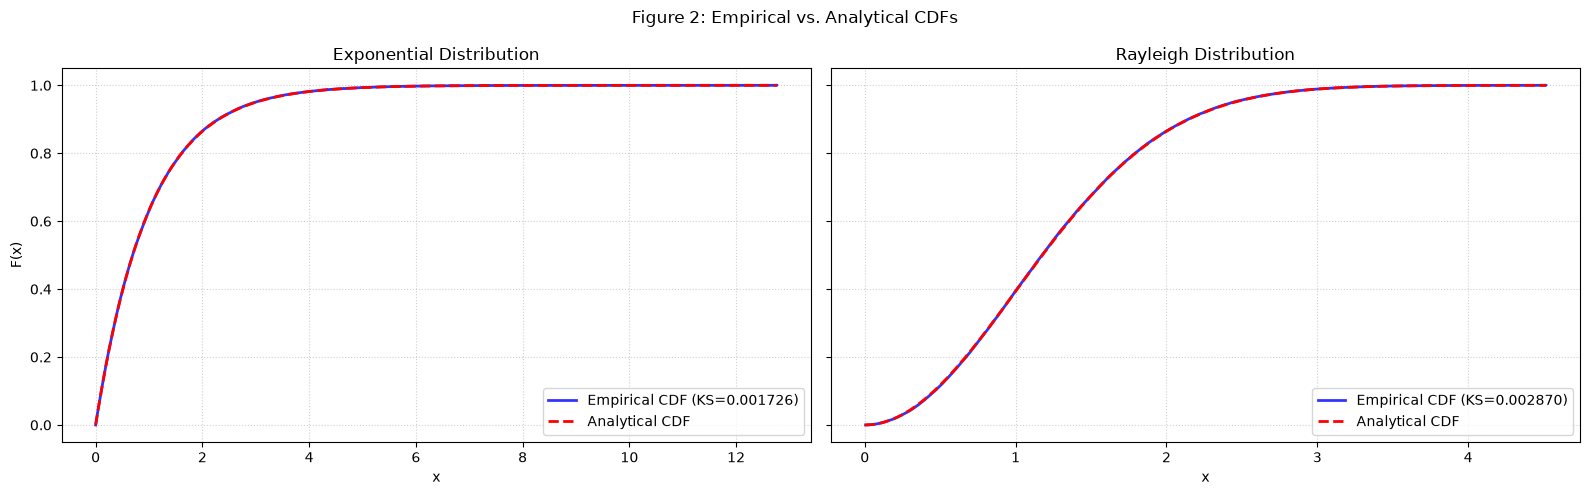

In [110]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

def cdf_comp_plot(inv_cdf_samp, stats_cdf, ks, name, i):
    sorted_samples = np.sort(inv_cdf_samp)
    ecdf = np.arange(1, len(sorted_samples) + 1) / len(sorted_samples)

    x_analytic = np.linspace(0, max(sorted_samples), 1000)
    y_analytic = stats_cdf(x_analytic)

    axes[i].step(sorted_samples, ecdf, label=f'Empirical CDF (KS={ks:.6f})', where='post', color='blue', linewidth=2, alpha=0.8)
    axes[i].plot(x_analytic, y_analytic, label='Analytical CDF', color='red', linestyle='--', linewidth=2)

    axes[i].set_title(f'{name} Distribution')
    axes[i].set_xlabel('x')
    axes[i].grid(True, linestyle=':', alpha=0.6)
    axes[i].legend(loc='lower right')
    
    return

cdf_comp_plot(inv_cdf_exp, stats.expon.cdf, ks_exp, "Exponential", 0)
cdf_comp_plot(inv_cdf_ray, stats.rayleigh.cdf, ks_ray, "Rayleigh", 1)

axes[0].set_ylabel("F(x)")
fig.suptitle("Figure 2: Empirical vs. Analytical CDFs")
fig.tight_layout()
plt.show()

### Question 5

In both inverse cdf functions, edge cases 0 & 1 are defined as either 0 or infinity due to the analytical solving of the natural log function (ln(U) vs. ln(1-U), where the uniform distribution, U, is defined by rng.random()). Because the support of rng.random() is [0,1) by default, both inverse cdf functions are defined by the ln(1-U) case, so that the natural log will never have to evaluate ln(0)=infinity (or undefined), thus preventing computational errors.

### Question 6

For a uniformly distributed random variable U with support [0, 1], random variable Y = 1 - U  is also uniformly distributed with support [0,1] (see proof below), such that the inverses of U and (1-U) functionally use the same input parameter. The natural log of 0 is undefined (except at a limit), and rng.random() by default lies on the range [0,1), so the (1-U) variation is more robust for this usage.

<br>

Proof:

$\text{Let } Y = 1 - U$

$\underline{U \in [0, 1] \hspace{5.8em} | \hspace{2em} F_{U}(u) = P(U \leq u) = u \hspace{1.8em}}$

$Y \in [1 - 1, 1 - 0] \hspace{2.3em} | \hspace{2em} F_{Y}(y) = P(1 - U \leq y)$

$\hspace{1em} \in [0, 1] \hspace{5.8em} | \hspace{2em} \hspace{2.6em} = P(U \geq 1 - y)$

$\hspace{9.8em} | \hspace{2em} \hspace{2.6em} = 1 - P(U < 1 - y)$

$\hspace{9.8em} | \hspace{2em} \hspace{2.6em} = 1 - (1 - y)$

$\hspace{9.8em} | \hspace{2em} \hspace{2.6em} = y$

$Y \in [0, 1] \hspace{5.8em} | \hspace{2em} F_{Y}(y) = y$

<br>

$\text{QED}$


## Step 3

### Question 1

$\text{Let } Y = X^{2}$

$F_{Y}(y) = P(Y \leq y)$

$F_{Y}(y) = P(-\sqrt{y} \leq X \leq \sqrt{y})$

$F_{Y}(y) = P(X \leq \sqrt{y}) - P(X < -\sqrt{y})$

$F_{Y}(y) = F_{X}(\sqrt{y}) - (1 - P(X \leq \sqrt{y})), \hspace{1em} \text{X is symmetric around zero}$

$F_{Y}(y) = 2 F_{X}(\sqrt{y}) - 1$

$F_{Y}(y) = 2 \Phi(\sqrt{y}) - 1$

$F_{Y}(y) = \frac{2}{\sqrt{2 \pi}} \int_{-\infty}^{\sqrt{y}} e^{-\frac{t^2}{2}} dt - 1 \hspace{1em} \text{or} \hspace{1em} F_{Y}(y) = erf(\sqrt{\frac{y}{2}})$

### Question 2

$f_{Y}(y) = \frac{d}{dy} (\frac{2}{\sqrt{2 \pi}} \int_{-\infty}^{\sqrt{y}} e^{-\frac{t^2}{2}} dt - 1)$

$f_{Y}(y) = \frac{2}{\sqrt{2 \pi}} e^{-\frac{y}{2}} \cdot \frac{1}{2} y^{-\frac{1}{2}}$

$f_{Y}(y) = \frac{1}{\sqrt{2 \pi y}} e^{-\frac{y}{2}}$

### Question 3

Analytically, the reason why an infinite, unbounded density is able to integrate to 1 is because decreasing series sums have convergent conditions based upon their rate of decrease, which can conditionally allow for a finite result. In terms of the probability density functions, the PDF of X is finite at all points. Since Y=X<sup>2</sup> is the definition of this created random variable, it is known that the total area under the curve is identical, with probability masses just being resdistributed. Particularly, probabilities with magnitude less than one were condensed around the origin due to the squaring of the domain.

In [111]:
def cdf_gauss_square(y):
    return special.erf(np.sqrt(y / 2))

def pdf_gauss_square(y):
    return 1 / np.sqrt(2 * np.pi * y) * np.exp(-y / 2)

print(f"{sp.integrate.quad(pdf_gauss_square, 0, np.inf)[0]:.4f}")

1.0000


### Question 4

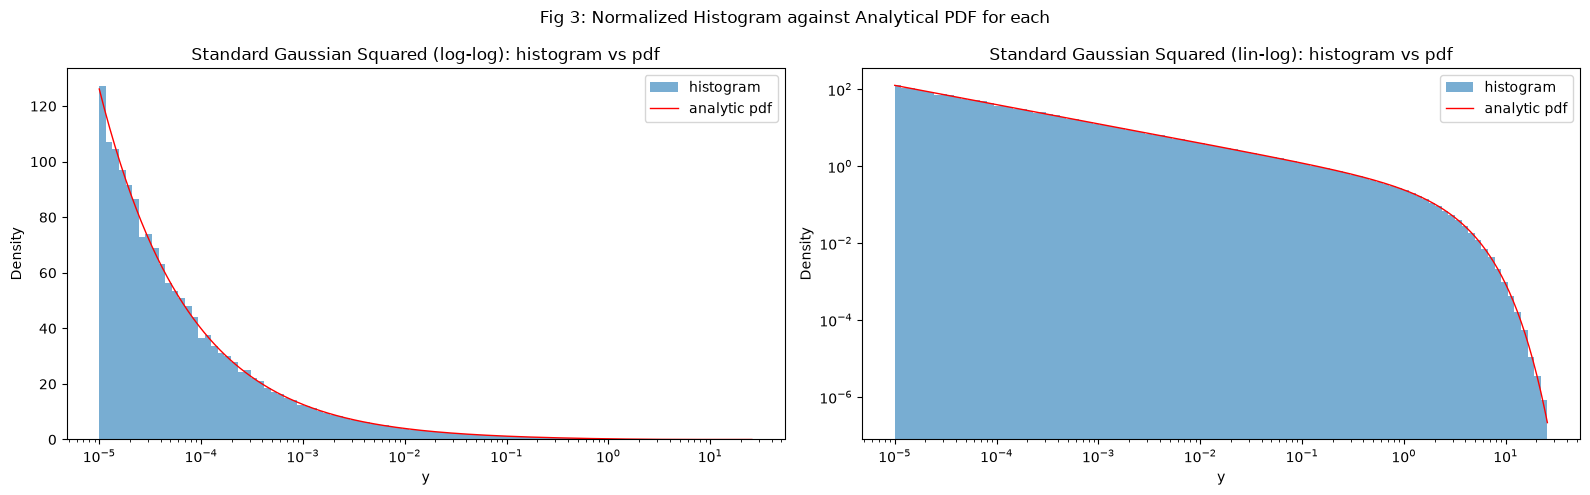

In [112]:
n = 10 ** 6

Y_samp = rng_3.normal(size=n) ** 2

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharex=True)
grid = np.logspace(np.log10(1e-5), np.log10(Y_samp.max()), 500)

styles = {"lin-log", "log-log"}

for ax, style in zip(axes, styles):
    ax.hist(Y_samp, bins=np.logspace(np.log10(1e-5), np.log10(Y_samp.max()), 100),
            density=True, alpha=0.6, label="histogram")
    ax.plot(grid, pdf_gauss_square(grid), "r-", lw=1, label="analytic pdf")
    ax.set_title(f"Standard Gaussian Squared ({style}): histogram vs pdf")
    ax.set_xlabel("y")
    ax.set_ylabel("Density")
    ax.legend()

axes[1].set_xscale("log")
axes[1].set_yscale("log")

fig.suptitle("Fig 3: Normalized Histogram against Analytical PDF for each")
fig.tight_layout()
plt.show()

The effective slope of the log-log graph is approximately $-\frac{1}{2}$. This is because the PDF function of this Chi-Square distribution is correlated by property $f(y) \propto y^{-\frac{1}{2}}e^{-\frac{y}{2}}$. As y approaches 0, the slope of the log-log graph becomes almost entirely controlled by the $y^{-\frac{1}{2}}$ term, with $\frac{d}{dy}|_{y=0^{+}} (y^{-\frac{1}{2}}) >> \frac{d}{dy}|_{y=0^{+}} (e^{-\frac{y}{2}})$ due to the asymptotic nature of the consequential $y^{-\frac{3}{2}}$ term in its derivative. Thus, examining the log-log slope of the simplified function yields $log(f(y)) \propto log(y^{-\frac{1}{2}}) = -\frac{1}{2} log(y)$, or a perceived slope of $-\frac{1}{2}$ near $y = 0$.

### Question 5

In [113]:
CDF1, CDF01 = cdf_gauss_square(1), cdf_gauss_square(0.1)
CDF1sim, CDF01sim = np.mean(Y_samp <= 1), np.mean(Y_samp <= 0.1)
Y_med = stats.chi2.median(df=1)
Y_med_sim = np.sort(Y_samp)[int(n / 2)]

print( "Theoretical:           "          +  "  | Simulation:            "                    + f"  | % error\n" +
       "-" * 63 + "\n" +
      f"P[Y \u2264 1.0] = {CDF1 :>10.4f}" + f"  | P[Y \u2264 1.0] \u2248 {CDF1sim :>10.4f}" + f"  | {percent_err(CDF1 , CDF1sim)  :.4f} %\n" +
      f"P[Y \u2264 0.1] = {CDF01:>10.4f}" + f"  | P[Y \u2264 0.1] \u2248 {CDF01sim:>10.4f}" + f"  | {percent_err(CDF01, CDF01sim) :.4f} %\n" +
      f"median =     {Y_med:>10.4f}"      + f"  | median \u2248     {Y_med_sim:>10.4f}"     + f"  | {percent_err(Y_med, Y_med_sim):.4f} %")

Theoretical:             | Simulation:              | % error
---------------------------------------------------------------
P[Y ≤ 1.0] =     0.6827  | P[Y ≤ 1.0] ≈     0.6820  | 0.1048 %
P[Y ≤ 0.1] =     0.2482  | P[Y ≤ 0.1] ≈     0.2484  | 0.0881 %
median =         0.4549  | median ≈         0.4563  | 0.3063 %


### Question 6

In [114]:
Y_mean = stats.chi2.mean(df=1)
Y_var = stats.chi2.var(df=1)
Y_mean_sim = Y_samp.mean()
Y_var_sim = stats.tvar(Y_samp)

print( "Theoretical:           "    +  "  | Simulation:            "                    + f"  | % error\n" +
       "-" * 63 + "\n" +
      f"mean =     {Y_mean:>12.3f}" + f"  | mean \u2248     {Y_mean_sim:>12.3f}" + f"  | {percent_err(Y_mean, Y_mean_sim):.4f} %\n" +
      f"variance = {Y_var :>12.3f}" + f"  | variance \u2248 {Y_var_sim :>12.3f}" + f"  | {percent_err(Y_var , Y_var_sim) :.4f} %")

Theoretical:             | Simulation:              | % error
---------------------------------------------------------------
mean =            1.000  | mean ≈            1.003  | 0.2825 %
variance =        2.000  | variance ≈        2.009  | 0.4537 %


## Step 4

### Question 1: 
For the Rayleigh with scale 1, derive or state the first four raw moments and verify each against 10<sup>6</sup> samples. Report the difference in units of standard error.

**Theoretical values for the first four raw moments**

Derivation of the closed-form equation

$$\mu '_n = \int_{0}^{\infty} x^n(\frac{x}{\sigma^2}e^{-\frac{x^2}{2\sigma^2}}) \,du$$

$$u=\frac{x^2}{2\sigma^2}, x=\sigma\sqrt{2u}$$

$$\mu '_n = \int_{0}^{\infty} (\sigma\sqrt{2u})^n e^{-u}
\,du = \sigma^n 2^{\frac{2}{n}}\int_{0}^{\infty} u^{\frac{n}{2}}e^{-u} \,du$$

$$\mu '_n = \sigma^n 2^{\frac{2}{n}}\Gamma(1+\frac{n}{2}), 
\text{where }\ \Gamma(1+\frac{n}{2}) = \int_{0}^{\infty} u^{\frac{n}{2}} e^{-u} \,du$$

---

With $\sigma = 1$ 

Raw moment of $n = 0$:

$$\mu '_1 = 1^1 2^{\frac{2}{1}}\Gamma(1+\frac{1}{2}) = 1.2533$$

Raw moment of $n = 1$:

$$\mu '_2 = 1^2 2^{\frac{2}{2}}\Gamma(1+\frac{2}{2}) = 2.0$$

Raw moment of $n = 2$:

$$\mu '_3 = 1^3 2^{\frac{2}{3}}\Gamma(1+\frac{3}{2}) = 3.7599$$

Raw moment of $n = 3$:

$$\mu '_4 = 1^4 2^{\frac{2}{4}}\Gamma(1+\frac{4}{2}) = 	8.0$$

In [115]:
# Generating the rayleigh of scale = 1 
n = 10**6
ray = rng_4.rayleigh(scale=1.0, size=n)

# raw moments theoretical
theo_raw = [1.2533, 2.0000, 3.7599, 8.0000]

# raw moments empirical
emp_raw = [0,0,0,0]
for m in range(1,5,1):
    emp_raw[m-1] = stats.moment(ray, order=m, center=0)

# Finding the difference in standard error units
SE = [0,0,0,0]
for m in range(1,5,1):
    SE[m-1] = ray.std() / (m**0.5)


# Difference in units  of standard error
d_SE = [0,0,0,0]
for m in range(1,5,1):
    d_SE[m-1] = (theo_raw[m-1]) / SE[m-1]
    # print(f"{d_SE[m-1]}")

print("Raw Moment (Theo.)\t| Raw Moment (Emp.)\t| SE\t\t\t| Diff in SE\n" + "-" * 88)
for i in range(0,4,1):
    print(f"{theo_raw[i]}\t\t\t| {emp_raw[i]:.4f}\t\t| {SE[i]:.4f}\t\t| {d_SE[i]:.4f}")

Raw Moment (Theo.)	| Raw Moment (Emp.)	| SE			| Diff in SE
----------------------------------------------------------------------------------------
1.2533			| 1.2541		| 0.6545		| 1.9148
2.0			| 2.0011		| 0.4628		| 4.3212
3.7599			| 3.7602		| 0.3779		| 9.9495
8.0			| 7.9932		| 0.3273		| 24.4446


### Question 2:

Now take a Pareto distribution with shape 1.5 and scale 1, whose density is 𝑓(𝑥) = 1.5 𝑥<sup>−2.5</sup> for 𝑥 ≥ 1. Show analytically that the mean exists and equals 3, and that the second moment does not exist.

Shape: $\alpha = 1.5$
Scale: $b = 1$

---

*Mean of Pareto distribution*

$$\mu = \frac{\alpha b}{\alpha-1} = 3.0$$

---

*Raw moment of Pareto distribution*

$$f(x) = \alpha\frac{b^\alpha}{x^{\alpha+1}} = 
1.5x^{-2.5} \ \text{for } x \geq 1$$

$$\mu'_n = \int^\infty _b x^n f(x) \,dx = 
\int^\infty _b \alpha\frac{b^\alpha}{x^{\alpha+1}} \,dx $$

$$\mu'_n = \alpha b^\alpha \int^\infty _b x^{n-\alpha-1} \,dx $$

$$\mu'_n = \alpha b^\alpha \left[\frac{x^{n-\alpha}}{n-\alpha}\right]^\infty _b  \ \text{for } n\leq a$$

At $n > \alpha$, the expression comes out to be $\infty$ due to the exponent at the numerator. To simplify it further it requires a restricted domain:

$$\mu'_n = \frac{\alpha b^n}{\alpha-n}, \ \text{for } n\leq a$$

Thus, while moment at $n = 1$ is:

$$\mu'_1 = \frac{\alpha b^1}{\alpha-1} = 3.0$$

the moment at $n = 2$ will be:

$$\mu'_n = \alpha b^\alpha \left[\frac{x^{2-\alpha}}{2-\alpha}\right]^\infty _b = \text{undefined}$$

### Question 3:

Compute the running sample mean and the running sample variance of Pareto samples at 𝑁 = 10<sup>3</sup>, 10<sup>4</sup>, 10<sup>5</sup>, 10<sup>6</sup>. Print both.

In [116]:
pareto_all_samples = rng_4.pareto(a=1.5, size=int(1e3+1e4+1e5+1e6)) + 1

def running_avg(amnt, array) -> float:
    return np.mean(array[0:int(amnt-1)])

def running_var(amnt, array) -> float:
    return np.var(array[0:int(amnt-1)])

print("Running Sample Mean at N +=\n" + "-"*35)
print(f"10^3: x\u0304 = {running_avg(amnt=1e3,array=pareto_all_samples):.4f}")
print(f"10^4: x\u0304 = {running_avg(amnt=1e3+1e4,array=pareto_all_samples):.4f}")
print(f"10^5: x\u0304 = {running_avg(amnt=1e3+1e4+1e5,array=pareto_all_samples):.4f}")
print(f"10^6: x\u0304 = {running_avg(amnt=1e3+1e4+1e5+1e6,array=pareto_all_samples):.4f}")

print("\nRunning Sample Variance at N +=\n"  + "-"*35)
print(f"10^3: \u03C3 = {running_var(amnt=1e3,array=pareto_all_samples):.4f}")
print(f"10^4: \u03C3 = {running_var(amnt=1e3+1e4,array=pareto_all_samples):.4f}")
print(f"10^5: \u03C3 = {running_var(amnt=1e3+1e4+1e5,array=pareto_all_samples):.4f}")
print(f"10^6: \u03C3 = {running_var(amnt=1e3+1e4+1e5+1e6,array=pareto_all_samples):.4f}")

Running Sample Mean at N +=
-----------------------------------
10^3: x̄ = 2.4630
10^4: x̄ = 2.9907
10^5: x̄ = 3.0410
10^6: x̄ = 2.9971

Running Sample Variance at N +=
-----------------------------------
10^3: σ = 7.3097
10^4: σ = 161.0558
10^5: σ = 328.4615
10^6: σ = 480.8940


### Question 4:

Explain what you observe: the sample mean settles near 3, while the sample variance wanders by factors of several and jumps whenever a large sample arrives. State in two sentences why the sample variance is still a number your code happily prints, and what that number actually represents.

This running sample mean settles near 3 while the variance continually increases because the first moment of this distribution converges towards a finite value while the second moment diverges towards infinity (given $\alpha=1.5$ and $b=1$). Sample variance is still a number Python will print due to how empirical distributions only handles finite quantities of data, meaning that array variance must also be finite.  

### Question 5:

State the practical rule this implies for anyone reporting an error bar on measured data.

Utilizing variance (such as in standard deviation and standard error) is considered to be a nonreliable method for reporting error bars in distributions with a heavy tail. In ones such as the pareton example, variance converges into infinity and thus becomes high numbers that do not accurately represent error bars.

## Step 5

## Step 6

## Step 7

### Question 1 

**Derive the false alarm probability of the envelope detector with threshold T.**

Noise only, so the magnitude is $R \sim \text{Rayleigh}(\sigma)$ with CDF $F_R(r) = 1 - e^{-r^2/2\sigma^2}$. A false alarm is $R > T$:

$$P_{FA} = P[R > T] = 1 - F_R(T) = e^{-T^2/2\sigma^2}$$

**Result:** $P_{FA} = e^{-T^2/2\sigma^2}$

### Question 2 

**Invert it.**

$$\ln P_{FA} = -\frac{T^2}{2\sigma^2} \;\Rightarrow\; T^2 = -2\sigma^2\ln P_{FA} \;\Rightarrow\; T = \sigma\sqrt{-2\ln P_{FA}}$$

**Answer:** $T = \sigma\sqrt{-2\ln P_{FA}}$. The table is printed by Cell 2 and repeated in the answers cell below.

In [2]:
# Parts 1-3: threshold table, then Monte Carlo check of the 1e-3 row
import numpy as np
import matplotlib.pyplot as plt

pfa_list = np.array([1e-2, 1e-3, 1e-4, 1e-6])
t_over_sigma = np.sqrt(-2 * np.log(pfa_list))
print(f"{'P_FA':<8s} {'T/sigma':>8s}")
for p, t in zip(pfa_list, t_over_sigma):
    print(f"{p:<8.0e} {t:8.4f}")

sigma, p_design, N = 1.0, 1e-3, 10**6
T = sigma * np.sqrt(-2 * np.log(p_design))
r = ml.sample_by_inversion(ml.inv_cdf_rayleigh, N, rng_7, sigma=sigma)
p_hat = np.mean(r > T)
se = np.sqrt(p_hat * (1 - p_hat) / N)
print(f"N = {N}, P_FA_hat = {p_hat:.3e}, SE = {se:.1e}, analytic = {p_design:.1e}")
print(f"difference in standard errors: {(p_hat - p_design) / se:+.2f}")

P_FA      T/sigma
1e-02      3.0349
1e-03      3.7169
1e-04      4.2919
1e-06      5.2565
N = 1000000, P_FA_hat = 1.007e-03, SE = 3.2e-05, analytic = 1.0e-03
difference in standard errors: +0.22


In [3]:
# Part 4: actual P_FA when the noise power is off, threshold fixed at the 1e-3 design value
db = np.array([-1, 0, 1, 2, 3])
k = 10 ** (db / 10)                      # true noise power / assumed noise power
p_actual = p_design ** (1 / k)

print(f"{'dB':>4s} {'actual P_FA':>12s} {'ratio':>7s}")
for d, pa in zip(db, p_actual):
    print(f"{d:+4d} {pa:12.3e} {pa / p_design:7.2f}")

  dB  actual P_FA   ratio
  -1    1.672e-04    0.17
  +0    1.000e-03    1.00
  +1    4.140e-03    4.14
  +2    1.280e-02   12.80
  +3    3.136e-02   31.36


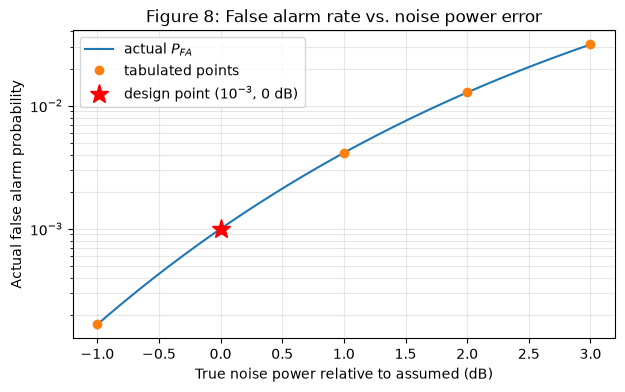

In [4]:
# Part 5: Figure 8
db_fine = np.linspace(-1, 3, 200)
p_fine = p_design ** (1 / 10 ** (db_fine / 10))

plt.figure(figsize=(7, 4))
plt.semilogy(db_fine, p_fine, label="actual $P_{FA}$")
plt.semilogy(db, p_actual, "o", label="tabulated points")
plt.semilogy(0, p_design, "r*", ms=14, label="design point ($10^{-3}$, 0 dB)")
plt.xlabel("True noise power relative to assumed (dB)")
plt.ylabel("Actual false alarm probability")
plt.title("Figure 8: False alarm rate vs. noise power error")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

### Question 2 

| $P_{FA}$ | $T/\sigma$ |
|---|---|
| $10^{-2}$ | 3.0349 |
| $10^{-3}$ | 3.7169 |
| $10^{-4}$ | 4.2919 |
| $10^{-6}$ | 5.2565 |

**Answer:** The $10^{-3}$ row matches the handout's check value of 3.7169.

### Question 3 
I checked the $P_{FA} = 10^{-3}$ row with $N = 10^6$ Rayleigh samples generated by inversion, using scale $\sigma = 1$.

**Answer:** The simulated $P_{FA}$ was $1.007\times10^{-3}$ with a standard error of $3.2\times10^{-5}$, against the analytic $10^{-3}$. The difference is 0.22 standard errors, so the simulation agrees with the formula.

### Question 4 
Suppose the true noise power is $k\sigma^2$ with $k = 10^{\text{dB}/10}$, so the true scale is $\sigma\sqrt{k}$. The threshold stays at its design value, $T^2 = -2\sigma^2\ln P_{design}$:

$$P_{FA,\text{actual}} = e^{-T^2/(2k\sigma^2)} = e^{\ln P_{design}/k} = P_{design}^{\,1/k}$$

| Noise error (dB) | Actual $P_{FA}$ | Ratio to design |
|---|---|---|
| −1 | $1.67\times10^{-4}$ | 0.17 |
| 0 | $1.00\times10^{-3}$ | 1.0 |
| +1 | $4.14\times10^{-3}$ | 4.1 |
| +2 | $1.28\times10^{-2}$ | 12.8 |
| +3 | $3.14\times10^{-2}$ | 31.4 |

**Answer:** At +1 dB the false alarm rate is 4.1 times the design value, and at +3 dB it is 31 times. These match the handout's check values.

### Question 5 
The curve shows actual $P_{FA}$ against noise power error, with the design point starred.

**Answer:** At +1 dB the actual $P_{FA}$ is $4.14\times10^{-3}$ (a factor of 4.14 over design), and at +3 dB it is $3.14\times10^{-2}$ (a factor of 31.4). At −1 dB it falls to $1.67\times10^{-4}$, which looks safe but means the detector is less sensitive than designed. The curve is steep because $P_{FA} = P_{design}^{1/k}$: the detector sits in the far tail, where probability depends exponentially on $T^2/2\sigma^2$, so a small error in the noise estimate becomes a large error in the false alarm rate.

### Question 6 
(fixed threshold, drifting noise):**

**Answer:** A fixed threshold in noise that drifts with temperature, interference, or clutter will have a false alarm rate that wanders by orders of magnitude, even when the noise power barely changes. The designer should stop fixing the threshold and estimate the noise level continuously from the data, for example from nearby reference cells, then scale the threshold to track it (constant false alarm rate, CFAR, detection). Adding threshold margin also helps, but it costs detection probability, so it is a poor substitute for adapting.


## Step 8

## Bonus A

**Symbolic Solutions**

Characteristic Equation Formula: $\phi_{X}(t) = \mathbb{E}[e^{itx}] = \int_{-\infty}^{+\infty} f(x)e^{itx} dx$

---

*Standard Gaussian:*

<br>

Probability Density Function:

$f(x) = \frac{1}{\sqrt{2 \pi}} e^{-\frac{x^{2}}{2}}$

<br>

Characteristic Equation:

$\phi_{X}(t) = \int_{-\infty}^{+\infty} (\frac{1}{\sqrt{2 \pi}} e^{-\frac{x^{2}}{2}}) e^{itx} dx$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} \int_{-\infty}^{+\infty} e^{-\frac{x^{2}}{2} + itx} dx$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} \int_{-\infty}^{+\infty} e^{-\frac{1}{2} (x^{2} - 2itx)} dx$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} \int_{-\infty}^{+\infty} e^{-\frac{1}{2} ((x-it)^{2}-(it)^{2})} dx$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} \int_{-\infty}^{+\infty} e^{-\frac{1}{2} (x-it)^{2} - \frac{t^{2}}{2}} dx$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} e^{-\frac{t^{2}}{2}} \int_{-\infty}^{+\infty} e^{-\frac{(x-it)^{2}}{2}} dx$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} e^{-\frac{t^{2}}{2}} \int_{-\infty - it}^{+\infty - it} e^{-\frac{z^{2}}{2}} dz \qquad
\begin{cases}
    z = x - it \\
    dz = dx
\end{cases}$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} e^{-\frac{t^{2}}{2}} \int_{-\infty}^{+\infty} e^{-\frac{u^{2}}{2}} du \qquad
\begin{cases}
    u = z + it & \text{(Cauchy's Integral Theorem simplification)} \\
    du = dz
\end{cases}$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} e^{-\frac{t^{2}}{2}}
\sqrt{(\int_{-\infty}^{+\infty} e^{-\frac{u_{x}^{2}}{2}} du_{x}) (\int_{-\infty}^{+\infty} e^{-\frac{u_{y}^{2}}{2}} du_{y})}$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} e^{-\frac{t^{2}}{2}}
\sqrt{\int_{-\infty}^{+\infty} \int_{-\infty}^{+\infty} e^{-\frac{u_{x}^{2} + u_{y}^{2}}{2}} du_{x} du_{y}}$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} e^{-\frac{t^{2}}{2}}
\sqrt{-\int_{0}^{2 \pi} \int_{0}^{\infty} -r \cdot e^{-\frac{r^{2}}{2}} dr d\theta} \qquad
\begin{cases}
    r^{2} = u_{x}^{2} + u_{y}^{2} & \text{(Cartesian to Polar)} \\
    du_{x} du_{y} = r dr d\theta
\end{cases}$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} e^{-\frac{t^{2}}{2}}
\sqrt{\int_{0}^{2 \pi} \lim\limits_{a \to \infty} [-e^{-\frac{r^{2}}{2}}]_{0}^{a} d\theta}$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} e^{-\frac{t^{2}}{2}} \sqrt{\int_{0}^{2 \pi} d\theta}$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} e^{-\frac{t^{2}}{2}} \sqrt{2 \pi - 0}$

$\phi_{X}(t) = e^{-\frac{t^{2}}{2}}$

---

*Exponential:*

PDF: $f(x) = \lambda e^{-\lambda x}$

<br>

Characteristic Equation:

$\phi_{X}(t) = \int_{0}^{\infty} (\lambda e^{-\lambda x}) e^{itx} dx$

$\hspace{2.7em} = \lambda \int_{0}^{\infty} e^{(it - \lambda) x} dx$

$\hspace{2.7em} = \frac{\lambda}{it - \lambda} \lim\limits_{a \to \infty}[e^{(it - \lambda) x}]_{0}^{a}$

$\hspace{2.7em} = \frac{\lambda}{it - \lambda} (-1) \qquad \text{(infinite attenuation by Euler's formula)}$

$\phi_{X}(t) = \frac{\lambda}{\lambda - it}$

## Bonus B